# YouTube Music listening analysis


This notebook analyzes **3,209 YouTube Music history entries** recorded from September 17, 2025 through February 16, 2026. Anacondaz leads the artist ranking with 299 entries (9.3% of the total). Counts represent history events—not confirmed full-song plays or listening duration.

The workflow cleans Google Takeout data, enriches artists with cached Last.fm tags, and explores artist, track, weekly, weekday, and hourly listening patterns.

## Context & Methods

The source is the local Google Takeout file `watch-history.json`. Only records labeled `YouTube Music` are included.

### Key assumptions

- One retained row is treated as one **history entry**, not a completed listen.
- Track rankings use `(artist, title)` so identically named tracks by different artists are not combined.
- Source timestamps are UTC and are converted to `America/Chicago` for behavioral time trends. Override `LOCAL_TIMEZONE` in `.env` if needed.
- Last.fm tags are community labels, so they can describe genre, geography, language, or scene.
- Stable Last.fm results (`ok` and `missing_tags`) are cached. Request failures are not cached and can be retried on the next run.

### 1. Setup

Credentials are read from the ignored `.env` file. The notebook uses only standard-library code to load it, so no dotenv package is required.

In [18]:
import json
import os # for environment variables
import time #for API throttling
from datetime import datetime, timezone 
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pylast # for Last.fm Access
from IPython.display import Markdown, display


def load_env_file(path=".env"):
    env_path = Path(path)
    if not env_path.exists():
        return
    for raw_line in env_path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip() #strip of spaces
        if not line or line.startswith("#") or "=" not in line:
            continue # if line in not useful skip it
        key, value = line.split("=", 1) # split only on the first "="
        os.environ.setdefault(key.strip(), value.strip())


load_env_file()

DATA_PATH = Path("watch-history.json")
CACHE_PATH = Path("lastfm_artist_tags_cache.json")
LOCAL_TIMEZONE = os.getenv("LOCAL_TIMEZONE", "America/Chicago")
LASTFM_API_KEY = os.getenv("LASTFM_API_KEY")
LASTFM_API_SECRET = os.getenv("LASTFM_API_SECRET")

BLUE = "#2563EB"
BLUE_DARK = "#1E3A5F"
GOLD = "#D49A22"
INK = "#263238"
GRID = "#D9E1E8"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "font.size": 10,
})

## Data

### 2. Load and clean the history

The title cleaner removes only a leading `Watched ` prefix, then trims surrounding whitespace. Artist names are extracted from the first subtitle record and normalized by removing a trailing ` - Topic`.

In [19]:
with DATA_PATH.open("r", encoding="utf-8") as file:
    raw_history = json.load(file)

history = pd.DataFrame(raw_history)
required_columns = {"header", "title", "subtitles", "time", "titleUrl"}
missing_columns = required_columns.difference(history.columns) # things in A that are not in B
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

music = history.loc[history["header"].eq("YouTube Music"), list(required_columns)].copy()
# loc select spesific row and colunmns
music["title"] = (
    music["title"]
    .str.replace(r"^Watched\s+", "", regex=True)
    .str.strip()
)

first_subtitle = music["subtitles"].apply(
    lambda value: value[0] if isinstance(value, list) and value else None
)
music["artist"] = first_subtitle.apply(
    lambda value: value.get("name") if isinstance(value, dict) else pd.NA
)
music["artist"] = (
    music["artist"]
    .astype("string")
    .str.replace(r"\s+- Topic$", "", regex=True)
    .str.strip()
)

music["listened_at_utc"] = pd.to_datetime(music["time"], format="ISO8601", utc=True)
music["listened_at_local"] = music["listened_at_utc"].dt.tz_convert(LOCAL_TIMEZONE)

extracted_video_id = music["titleUrl"].str.extract(r"[?&]v=([^&]+)", expand=False)
music["video_id"] = extracted_video_id.fillna(music["titleUrl"])

listening = (
    music[["title", "artist", "listened_at_utc", "listened_at_local", "video_id"]]
    .sort_values("listened_at_utc")
    .reset_index(drop=True)
)

listening.head()

,title,artist,listened_at_utc,listened_at_local,video_id
0,Jigsaw Falling Into Place,Radiohead,2025-09-17 11:14:41.340000+00:00,2025-09-17 06:14:41.340000-05:00,CvjRlYpXS5U
1,Мой рок-н-ролл,Би-2,2025-09-17 11:18:36.687000+00:00,2025-09-17 06:18:36.687000-05:00,jtr2q0GRDGA
2,Обломки чувств,Noize MC,2025-09-17 11:25:23.068000+00:00,2025-09-17 06:25:23.068000-05:00,TB5MfV4Qd6Y
3,Ta reine,Angèle,2025-09-17 11:25:39.233000+00:00,2025-09-17 06:25:39.233000-05:00,KHr1snPlgMU
4,One Way,Twenty One Pilots,2025-09-17 12:28:05.748000+00:00,2025-09-17 07:28:05.748000-05:00,mWUsIaZHfZo


### 3. Validate the prepared data

These checks protect the analysis from accidental row loss, invalid timestamps, and duplicate enrichment joins later in the notebook.

In [20]:
quality_summary = pd.Series({
    "all history rows": len(history),
    "YouTube Music rows": len(listening),
    "unique video IDs": listening["video_id"].nunique(),
    "unique artists": listening["artist"].nunique(),
    "missing artists": listening["artist"].isna().sum(),
    "missing timestamps": listening["listened_at_utc"].isna().sum(),
    "first entry (UTC)": listening["listened_at_utc"].min(),
    "last entry (UTC)": listening["listened_at_utc"].max(),
})

assert len(listening) == history["header"].eq("YouTube Music").sum()
assert listening["listened_at_utc"].notna().all()
assert not listening["title"].str.startswith("Watched ", na=False).any()

quality_summary.to_frame("value")

,value
all history rows,14700
YouTube Music rows,3209
unique video IDs,1853
unique artists,942
missing artists,3
missing timestamps,0
first entry (UTC),2025-09-17 11:14:41.340000+00:00
last entry (UTC),2026-02-16 00:07:27.648000+00:00


### 4. Enrich artists with cached Last.fm tags

Each unique artist is requested at most once. `tag_status` distinguishes successful tags, artists with no tags, missing artist names, and temporary request failures. After three consecutive API failures, remaining uncached artists are marked `not_requested` so an outage does not trigger hundreds of calls.

In [21]:
def load_tag_cache(path):
    if not path.exists():
        return {}
    try:
        cached = json.loads(path.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError) as exc:
        raise RuntimeError(f"Could not read tag cache {path}: {exc}") from exc
    if not isinstance(cached, dict):
        raise ValueError("Last.fm cache must contain a JSON object")
    return cached


def save_tag_cache(cache, path):
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    temporary_path.write_text(
        json.dumps(cache, ensure_ascii=False, indent=2, sort_keys=True),
        encoding="utf-8",
    )
    temporary_path.replace(path)


def fetch_artist_tags(artist, network, cache, force_refresh=False):
    if pd.isna(artist) or not str(artist).strip():
        return {
            "artist": artist,
            "tags": [],
            "tag_status": "artist_missing",
            "tag_error": None,
            "tag_source": "local",
        }

    artist = str(artist)
    if artist in cache and not force_refresh:
        return {"artist": artist, **cache[artist], "tag_source": "cache"}

    if network is None:
        return {
            "artist": artist,
            "tags": [],
            "tag_status": "not_requested",
            "tag_error": "Last.fm credentials are unavailable",
            "tag_source": "local",
        }

    try:
        tags = [tag.item.name for tag in network.get_artist(artist).get_top_tags(limit=3)]
    except pylast.WSError as exc:
        return {
            "artist": artist,
            "tags": [],
            "tag_status": "request_failed",
            "tag_error": f"Last.fm API error: {exc}",
            "tag_source": "api",
        }
    except (pylast.NetworkError, pylast.MalformedResponseError) as exc:
        return {
            "artist": artist,
            "tags": [],
            "tag_status": "request_failed",
            "tag_error": f"Last.fm network/response error: {exc}",
            "tag_source": "api",
        }
    except (OSError, TimeoutError, ConnectionError) as exc:
        return {
            "artist": artist,
            "tags": [],
            "tag_status": "request_failed",
            "tag_error": f"Local network error: {exc}",
            "tag_source": "api",
        }

    stable_result = {
        "tags": tags,
        "tag_status": "ok" if tags else "missing_tags",
        "tag_error": None,
        "fetched_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    cache[artist] = stable_result
    save_tag_cache(cache, CACHE_PATH)
    time.sleep(0.1)
    return {"artist": artist, **stable_result, "tag_source": "api"}


tag_cache = load_tag_cache(CACHE_PATH)
lastfm_network = None
if LASTFM_API_KEY and LASTFM_API_SECRET:
    lastfm_network = pylast.LastFMNetwork(
        api_key=LASTFM_API_KEY,
        api_secret=LASTFM_API_SECRET,
    )

artist_names = listening["artist"].dropna().drop_duplicates().sort_values()
tag_records = []
consecutive_failures = 0

for position, artist in enumerate(artist_names):
    result = fetch_artist_tags(artist, lastfm_network, tag_cache)
    tag_records.append(result)
    if result["tag_status"] == "request_failed":
        consecutive_failures += 1
    else:
        consecutive_failures = 0

    if consecutive_failures >= 3:
        for remaining_artist in artist_names.iloc[position + 1:]:
            tag_records.append({
                "artist": remaining_artist,
                "tags": [],
                "tag_status": "not_requested",
                "tag_error": "Stopped after three consecutive API failures",
                "tag_source": "local",
            })
        break

artist_tags = pd.DataFrame(tag_records)
artist_tags["tags_text"] = artist_tags["tags"].apply(
    lambda tags: ", ".join(tags) if isinstance(tags, list) and tags else pd.NA
)

before_merge_rows = len(listening)
listening = listening.merge(
    artist_tags[["artist", "tags", "tags_text", "tag_status", "tag_error", "tag_source"]],
    on="artist",
    how="left",
    validate="many_to_one",
)
listening[["tag_status", "tag_source"]] = listening[["tag_status", "tag_source"]].fillna("artist_missing")
assert len(listening) == before_merge_rows

artist_tags["tag_status"].value_counts(dropna=False).to_frame("artists")

,artists
tag_status,
ok,803
missing_tags,135
request_failed,4


## Results

### 5. Rank artists and tracks

The artist ranking counts all history entries. The track ranking groups by both artist and title to avoid combining unrelated tracks that share a name.

In [22]:
artist_ranking = (
    listening.groupby("artist", dropna=False)
    .size()
    .rename("history_entries")
    .reset_index()
    .sort_values("history_entries", ascending=False)
)

track_ranking = (
    listening.groupby(["artist", "title"], dropna=False)
    .size()
    .rename("history_entries")
    .reset_index()
    .sort_values("history_entries", ascending=False)
)

display(artist_ranking.head(10))
display(track_ranking.head(10))

,artist,history_entries
51,Anacondaz,299
545,Oxxxymiron,183
526,Noize MC,127
411,Lorien Testard,119
210,Egor Kreed,107
772,Twenty One Pilots,105
779,Ulukmanapo,71
25,ATL,48
585,Radiohead,43
173,Dayte tank (!),32


,artist,title,history_entries
161,Anacondaz,Хорошая сторона,31
1225,Radiohead,Jigsaw Falling Into Place,22
111,Anacondaz,Внутренняя эмиграция,22
1145,Oxxxymiron,Лондонград,21
151,Anacondaz,Скейтборд,19
109,Anacondaz,В одного,17
1132,Oxxxymiron,Город под подошвой,17
147,Anacondaz,Рэп и деградация,17
1682,nobodyknows+,Hero's Come Back!!,17
1155,Oxxxymiron,Пантеллерия,17


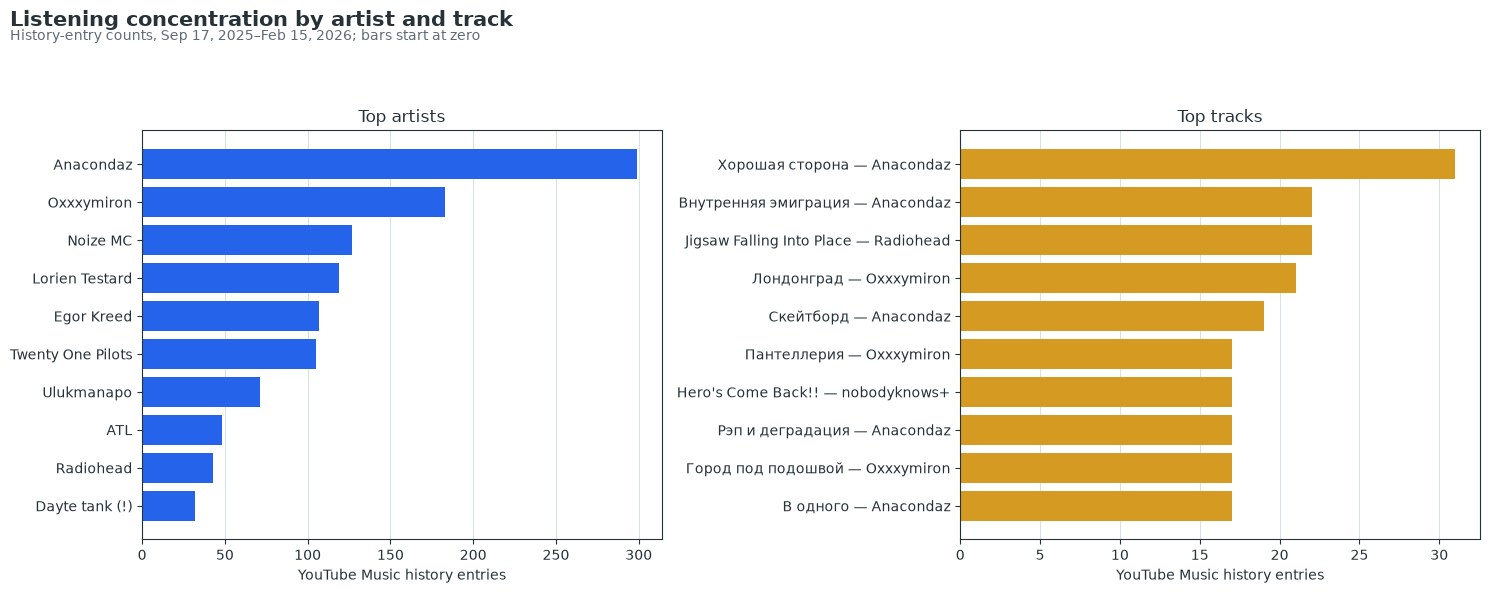

In [23]:
top_artists = artist_ranking.head(10).sort_values("history_entries")
top_tracks = track_ranking.head(10).copy()
top_tracks["track_label"] = top_tracks["title"] + " — " + top_tracks["artist"].fillna("Unknown artist")
top_tracks = top_tracks.sort_values("history_entries")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(top_artists["artist"].fillna("Unknown artist"), top_artists["history_entries"], color=BLUE)
axes[0].set_title("Top artists")
axes[0].set_xlabel("YouTube Music history entries")
axes[0].set_xlim(left=0)
axes[0].grid(axis="x", color=GRID, linewidth=0.8)
axes[0].set_axisbelow(True)

axes[1].barh(top_tracks["track_label"], top_tracks["history_entries"], color=GOLD)
axes[1].set_title("Top tracks")
axes[1].set_xlabel("YouTube Music history entries")
axes[1].set_xlim(left=0)
axes[1].grid(axis="x", color=GRID, linewidth=0.8)
axes[1].set_axisbelow(True)

fig.suptitle(
    "Listening concentration by artist and track",
    fontsize=15,
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.text(
    0.01,
    0.93,
    f"History-entry counts, {listening['listened_at_local'].min():%b %d, %Y}–{listening['listened_at_local'].max():%b %d, %Y}; bars start at zero",
    color="#5F6B76",
)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

### 6. Explore listening over time

Weekly counts show the longer-run shape across more than 20 observed weeks. Weekday and hour-of-day views use local time and describe when history entries occurred, not listening duration.

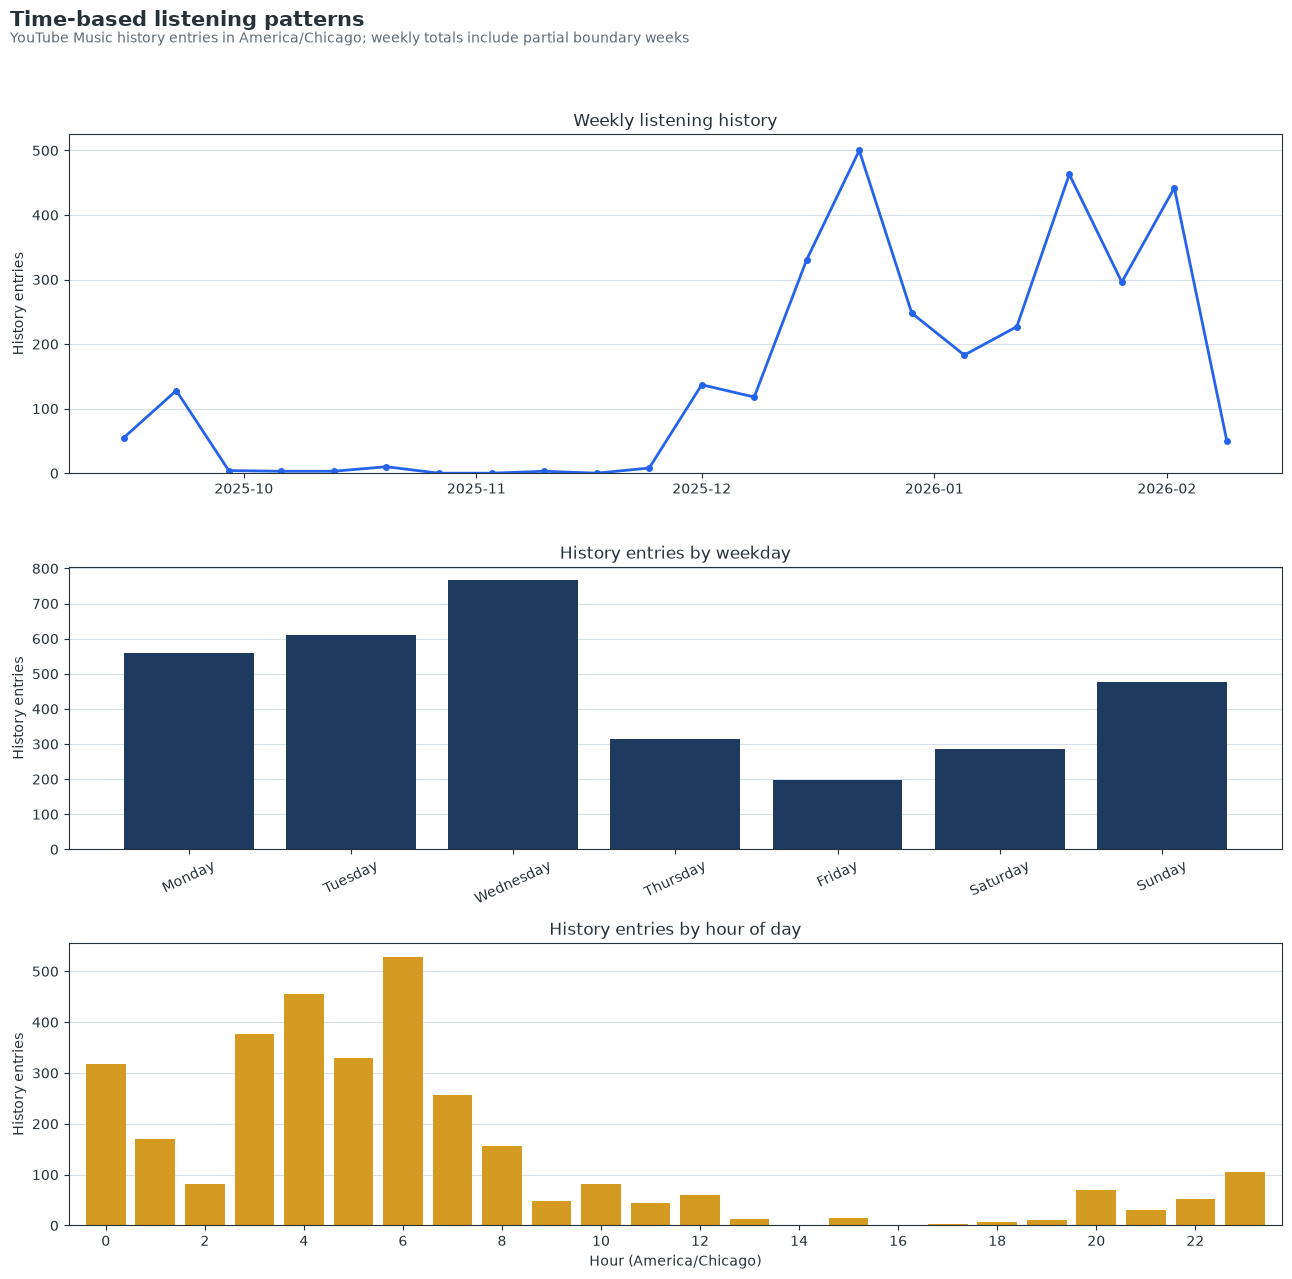

In [24]:
weekly_listening = (
    listening.set_index("listened_at_local")
    .resample("W-MON", label="left", closed="left")
    .size()
    .rename("history_entries")
)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_listening = (
    listening["listened_at_local"].dt.day_name()
    .value_counts()
    .reindex(weekday_order, fill_value=0)
)

hourly_listening = (
    listening["listened_at_local"].dt.hour
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

fig, axes = plt.subplots(3, 1, figsize=(13, 13), gridspec_kw={"height_ratios": [1.2, 1, 1]})

axes[0].plot(weekly_listening.index, weekly_listening.values, color=BLUE, marker="o", markersize=4, linewidth=2)
axes[0].set_title("Weekly listening history")
axes[0].set_ylabel("History entries")
axes[0].set_ylim(bottom=0)
axes[0].grid(axis="y", color=GRID, linewidth=0.8)

axes[1].bar(weekday_listening.index, weekday_listening.values, color=BLUE_DARK)
axes[1].set_title("History entries by weekday")
axes[1].set_ylabel("History entries")
axes[1].set_ylim(bottom=0)
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", color=GRID, linewidth=0.8)

axes[2].bar(hourly_listening.index, hourly_listening.values, color=GOLD, width=0.8)
axes[2].set_title("History entries by hour of day")
axes[2].set_xlabel(f"Hour ({LOCAL_TIMEZONE})")
axes[2].set_ylabel("History entries")
axes[2].set_xticks(range(0, 24, 2))
axes[2].set_xlim(-0.75, 23.75)
axes[2].set_ylim(bottom=0)
axes[2].grid(axis="y", color=GRID, linewidth=0.8)

for axis in axes:
    axis.set_axisbelow(True)

fig.suptitle("Time-based listening patterns", fontsize=15, fontweight="bold", x=0.01, ha="left")
fig.text(
    0.01,
    0.955,
    f"YouTube Music history entries in {LOCAL_TIMEZONE}; weekly totals include partial boundary weeks",
    color="#5F6B76",
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### 7. Inspect Last.fm coverage

Coverage is reported at the unique-artist level. Request failures remain visibly different from legitimate artists that returned no tags.

In [25]:
tag_coverage = (
    artist_tags["tag_status"]
    .value_counts(dropna=False)
    .rename_axis("tag_status")
    .reset_index(name="artists")
)
tag_coverage["share"] = tag_coverage["artists"] / len(artist_tags)

top_artist_tags = (
    artist_ranking.head(10)
    .merge(artist_tags[["artist", "tags_text", "tag_status", "tag_source"]], on="artist", how="left", validate="one_to_one")
)

tag_coverage_display = tag_coverage.assign(
    share=tag_coverage["share"].map("{:.1%}".format)
)
display(tag_coverage_display)
display(top_artist_tags)

,tag_status,artists,share
0,ok,803,85.2%
1,missing_tags,135,14.3%
2,request_failed,4,0.4%


,artist,history_entries,tags_text,tag_status,tag_source
0,Anacondaz,299,"Hip-Hop, underground hip-hop, russian",ok,cache
1,Oxxxymiron,183,"Hip-Hop, Grime, rap",ok,cache
2,Noize MC,127,"Hip-Hop, rapcore, rap",ok,cache
3,Lorien Testard,119,"Soundtrack, instrumental, video game music",ok,cache
4,Egor Kreed,107,"Russia, russian",ok,cache
5,Twenty One Pilots,105,"electronic, alternative, rap",ok,cache
6,Ulukmanapo,71,"rap, Hip-Hop, kyrgyz",ok,cache
7,ATL,48,"Hip-Hop, rap, russian",ok,cache
8,Radiohead,43,"rock, alternative, alternative rock",ok,cache
9,Dayte tank (!),32,"russian, rock",ok,cache


## Takeaways

The final cell generates conclusions directly from the prepared tables so the narrative stays aligned with the latest notebook run.

In [26]:
top_artist = artist_ranking.iloc[0]
top_track = track_ranking.iloc[0]
busiest_weekday = weekday_listening.idxmax()
peak_hour = int(hourly_listening.idxmax())
peak_week_start = weekly_listening.idxmax()
successful_tag_share = artist_tags["tag_status"].eq("ok").mean()

display(Markdown(f'''
### Conclusions

- **Listening concentration:** {top_artist['artist']} leads with **{top_artist['history_entries']:,}** of **{len(listening):,}** history entries ({top_artist['history_entries'] / len(listening):.1%}).
- **Most frequent track:** “{top_track['title']}” by {top_track['artist']} appears **{top_track['history_entries']:,}** times.
- **Weekly peak:** the week beginning **{peak_week_start:%B %d, %Y}** has the largest recorded total at **{weekly_listening.max():,}** entries. Boundary weeks are partial.
- **Timing:** {busiest_weekday} is the busiest weekday, and the busiest local hour starts at **{peak_hour:02d}:00** ({LOCAL_TIMEZONE}).
- **Tag coverage:** Last.fm returned at least one tag for **{successful_tag_share:.1%}** of unique enriched artists. Review the coverage table before using tags as a complete genre taxonomy.

These findings describe recorded history events. They do not measure completed plays, unique listening sessions, or listening duration.
'''))


### Conclusions

- **Listening concentration:** Anacondaz leads with **299** of **3,209** history entries (9.3%).
- **Most frequent track:** “Хорошая сторона” by Anacondaz appears **31** times.
- **Weekly peak:** the week beginning **December 22, 2025** has the largest recorded total at **500** entries. Boundary weeks are partial.
- **Timing:** Wednesday is the busiest weekday, and the busiest local hour starts at **06:00** (America/Chicago).
- **Tag coverage:** Last.fm returned at least one tag for **85.2%** of unique enriched artists. Review the coverage table before using tags as a complete genre taxonomy.

These findings describe recorded history events. They do not measure completed plays, unique listening sessions, or listening duration.
